# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 4. Создаем GPT-0.001 в <s>гаражных</s> общажных условиях.


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 40 баллов;
* Задача 2 &mdash; 60 баллов.

In [110]:
import json
import os
import re
import urllib.request
from collections import Counter
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from navec import Navec
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from tqdm.notebook import tqdm
from sklearn.linear_model import SGDClassifier

sns.set_theme(style="whitegrid", palette="Set2")

In [111]:
# Bot check

# HW_ID: fpmi_ad4
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1, 2**
1. https://chat.deepseek.com/share/j4dgagsywrq6pn7ty3
- задавала вопросы: теория, синтаксис, примеры


### 📌 Примечание

**Задача 2:**

**Исправлено:**
▫️ Нет идей по улучшению модели при больших вычислительных ресурсах.
- В финальном выводе добавлено обсуждение идей по улучшению модели при наличии больших вычислительных ресурсов.

---

На лекции мы обсуждали, как работают современные языковые модели (LLM) наподобие ChatGPT: они используют архитектуру Transformer, механизм внимания (Self-Attention) и предсказывают следующий токен. Звучит как магия из мира бигтеха, правда?

Конечно, пока вы не знаете, как математически писать и обучать глубокие нейронные сети. Но знаете что? Чтобы построить **нашу собственную GPT-0.001** прямо здесь, на ваших ноутбуках в корридорах ваших общаг, вам это и не нужно! 

Фундаментальные принципы современных моделей можно понять и воспроизвести с помощью базовых инструментов, которые вы уже знаете:
* логистическая регрессия послужит нам финальным слоем предсказания,
* для представления текста в виде векторов будем использовать One-Hot преобразование,
* а понять смыслы слов на поможет старый добрый KNN!

В этом задании мы с вами шаг за шагом пройдем путь от простейшего генератора текста (символьной модели) до создания собственного механизма динамического внимания (Attention). Поехали!

---
### Задача 1.

#### 1. Данные: на чем будем учить?

Скачайте файл: [all_django.json](https://github.com/IlyaGusev/PoetryCorpus/blob/master/datasets/django/all_django.json) — это корпус стихов русских поэтов.

**Почему именно стихи?**
Обучать языковую модель с нуля на Википедии — задача для суперкомпьютеров. Наша общажная модель с таким не справится (у нас просто не хватит оперативной памяти и времени). А вот стихи — это идеальная "игрушечная вселенная" для языковой модели по нескольким причинам:
* В стихах есть рифма и ритм. Вероятность появления определенных слов или окончаний в конце строки сильно выше.
* Поэты часто используют устойчивые эпитеты («мороз и солнце», «буря мглою», «парус одинокий»). Модели будет проще выучить эти локальные зависимости.
* Лексика поэтов (особенно классиков) пересекается, что сильно упрощает задачу классификации для нашей логистической регрессии.

*Замечание.*  На самом деле не стоит думать, что стихи — это «просто». В реальности поэзия — одна из самых сложных доменных областей: омографы, где смысл и ударение зависят от контекста, инверсии, авторская пунктуация, метафоры с неочевидными семантическими связями. Полноценная генерация стихов с правильным размером и осмысленным содержанием — до сих пор не до конца решенная задача.

Давайте загрузим датасет и посмотрим на него.

In [113]:
with open("all_django.json", "r", encoding="utf-8") as f:
    all_poems = json.load(f)

data = []
for poem in all_poems:
    data.append(
        {
            "author": poem["fields"]["author"],
            "text": poem["fields"]["text"],
        }
    )

data = pd.DataFrame(data)
data["length"] = data["text"].str.len()  # количество символов
data.head()

,author,text,length
0,Михаил Лермонтов,"Забывши волнения жизни мятежной,\nОдин жил в п...",193
1,Сергей Есенин,"Нивы сжаты, рощи голы,\nОт воды туман и сырост...",291
2,Игорь Северянин,Лючинь печальная читала вечером ручьисто-вкрад...,611
3,Анатолий Жигулин,"Глыбу кварца разбили молотом,\nИ, веселым огне...",745
4,Николай Тихонов,"Хлынул дождь, когда девушки, встав в хоровод,\...",532


В данных представлено довольно много стихов

In [114]:
len(data)

16694

Посмотрим на один случайный стих

In [115]:
np.random.seed(36)

random_poem_index = np.random.choice(range(len(data)))
print(data.iloc[random_poem_index, 1])

(Отрывок)
Я помню бал. Горели ярко свечи,
И группы пестрые мелькали предо мной.
Я слушал то отрывистые речи,
То Ланнера мотив унылый и простой.
Но слушал их небрежно и зевая,
А взорами ее - одну ее искал.
Где ты, всегда нарядная, живая,
Как мотылек? Тебя давно я не видал,
Но все к тебе мои неслися думы,
Тобой и в этот миг они еще полны;
И жду тебя, усталый и угрюмый,
Я, как природа ждет дыхания весны!
И длился скучный бал до поздней ночи,
Я покидал его с досадою немой,
Но вдруг ее лазуревые очи,
Как будто две звезды, зажглися предо мной.
И увидал я вновь, отрады полный,
И плечи белые, как первый снег полей,
И смоляных волос густые волны,
И легкий стройный стан красавицы моей.
Но на щеках нет прежнего румянца...
Ты улыбаешься сквозь слезы? Ты грустна?
Устала ль ты, кружася в вихре танца,
Иль скорбь на дне души твоей затаена?
Ужель и ты обманута мечтами
И на страдания судьбой обречена?..
Вот руку мне дрожащими руками
Схватив, "Я замужем",- произнесла она;
А грудь ее высоко волновалась,
И

Проведите базовый разведочный анализ данных.
* Определите топ-10 писателей по количеству стихов.
* Постройте гистограмму длины стихов (по количеству символов).
* Определите, какой стих самый длинный.

In [118]:
# Базовый разведочный анализ данных
print("Размер таблицы:", data.shape)
print("\nПропуски:")
print(data.isna().sum())

print("\nСтатистика по длине стихов:")
print(data["length"].describe())

Размер таблицы: (16694, 3)

Пропуски:
author    0
text      0
length    0
dtype: int64

Статистика по длине стихов:
count    16694.000000
mean       791.187852
std       1016.792106
min         21.000000
25%        370.000000
50%        555.000000
75%        881.000000
max      28243.000000
Name: length, dtype: float64


In [120]:
# Топ-10 писателей по количеству стихов
top_10_authors = (
    data["author"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_10_authors.columns = ["author", "poems_count"]
top_10_authors

,author,poems_count
0,Владимир Высоцкий,539
1,Александр Пушкин,401
2,Александр Блок,286
3,Анна Ахматова,277
4,Афанасий Фет,251
5,Федор Тютчев,242
6,Илья Эренбург,237
7,Михаил Лермонтов,234
8,Федор Сологуб,230
9,Валерий Брюсов,211


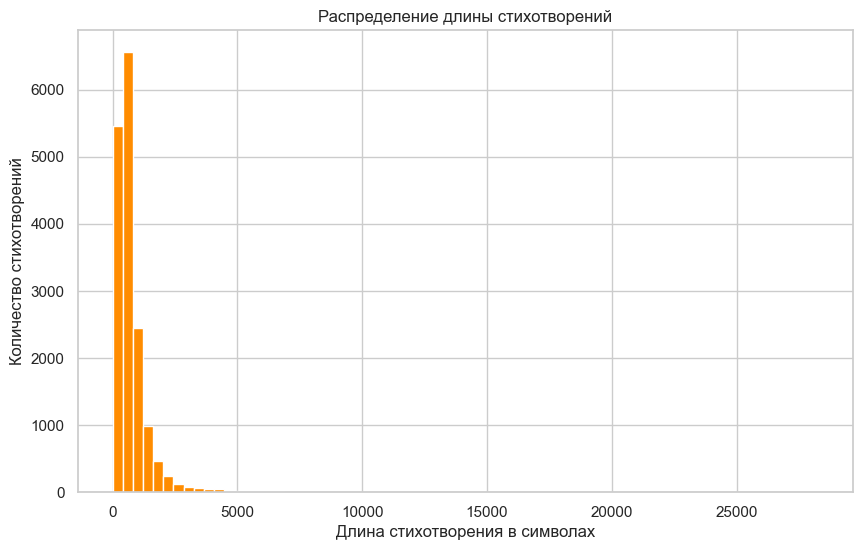

In [125]:
# Гистограмма длины стихов
plt.figure(figsize=(10, 6))
plt.hist(data["length"], bins=70, color="darkorange")
plt.xlabel("Длина стихотворения в символах")
plt.ylabel("Количество стихотворений")
plt.title("Распределение длины стихотворений")
plt.show()

In [126]:
# Самый длинный стих
longest_poem_index = data["length"].idxmax()

print("Автор:", data.loc[longest_poem_index, "author"])
print("Длина:", data.loc[longest_poem_index, "length"])
print("\nТекст стихотворения:\n")
print(data.loc[longest_poem_index, "text"])

Автор: Николай Некрасов
Длина: 28243

Текст стихотворения:

Посвящаю моей сестре
Анне Алексеевне.
Ты опять упрекнула меня,
Что я с музой моей раздружился,
Что заботам текущего дня
И забавам его подчинился.
Для житейских расчетов и чар
Не расстался б я с музой моею,
Но бог весть, не погас ли тот дар,
Что, бывало, дружил меня с нею?
Но не брат еще людям поэт,
И тернист его путь, и непрочен,
Я умел не бояться клевет,
Не был ими я сам озабочен;
Но я знал, чье во мраке ночном
Надрывалося сердце с печали,
И на чью они грудь упадали свинцом,
И кому они жизнь отравляли.
И пускай они мимо прошли,
Надо мною ходившие грозы,
Знаю я, чьи молитвы и слезы
Роковую стрелу отвели...
Да и время ушло,— я устал...
Пусть я не был бойцом без упрека,
Но я силы в себе сознавал,
Я во многое верил глубоко,
А теперь — мне пора умирать...
Не затем же пускаться в дорогу,
Чтобы в любящем сердце опять
Пробудить роковую тревогу...
Присмиревшую музу мою
Я и сам неохотно ласкаю...
Я последнюю песню пою
Для тебя — и тебе

**Вывод:**

В датасете содержится 16 694 стихотворения и 3 столбца: автор, текст стихотворения и его длина. 
Пропущенных значений в данных нет.

Средняя длина стихотворения составляет примерно **791 символ**, медианная длина — **555 символов**, 
что говорит о том, что большинство стихов относительно небольшие. 
При этом длина стихов распределена неравномерно: встречаются как очень короткие, так и очень длинные произведения. 
Минимальная длина стихотворения равна **21 символ**, а максимальная достигает **28 243 символов**.

По количеству стихотворений лидируют следующие авторы:
- Владимир Высоцкий — **539 стихотворений**
- Александр Пушкин — **401**
- Александр Блок — **286**
- Анна Ахматова — **277**
- Афанасий Фет — **251**

Самое длинное стихотворение принадлежит **Николаю Некрасову**, его длина составляет **28 243 символа**.

Таким образом, датасет содержит достаточно большое количество стихотворений разных авторов и широкий диапазон длин текстов, что делает его подходящим для обучения простой символьной языковой модели.



Поскольку мы создаем самую простую модель (да еще и на CPU ваших компьютеров), нам нужно максимально облегчить ей жизнь. Любая пунктуация, заглавные буквы и переносы строк — это "лишний шум", на распознавание которого модели придется тратить свои силы. 

Поэтому мы проведем жесткую предобработку

In [127]:
# Переводим в нижний регистр
data["text"] = data["text"].str.lower()
# Заменяем переносы строк на пробелы
data["text"] = data["text"].str.replace("\n", " ", regex=False)
# Оставляем только буквы и пробелы
data["text"] = data["text"].str.replace(r"[^а-яё\s]", "", regex=True)
# Убираем множественные пробелы
data["text"] = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

Посмотрим, как теперь выглядит стих. Он превратился в непрерывный поток слов

In [128]:
print(data.iloc[random_poem_index, 1])

отрывок я помню бал горели ярко свечи и группы пестрые мелькали предо мной я слушал то отрывистые речи то ланнера мотив унылый и простой но слушал их небрежно и зевая а взорами ее одну ее искал где ты всегда нарядная живая как мотылек тебя давно я не видал но все к тебе мои неслися думы тобой и в этот миг они еще полны и жду тебя усталый и угрюмый я как природа ждет дыхания весны и длился скучный бал до поздней ночи я покидал его с досадою немой но вдруг ее лазуревые очи как будто две звезды зажглися предо мной и увидал я вновь отрады полный и плечи белые как первый снег полей и смоляных волос густые волны и легкий стройный стан красавицы моей но на щеках нет прежнего румянца ты улыбаешься сквозь слезы ты грустна устала ль ты кружася в вихре танца иль скорбь на дне души твоей затаена ужель и ты обманута мечтами и на страдания судьбой обречена вот руку мне дрожащими руками схватив я замужем произнесла она а грудь ее высоко волновалась и томный взор горел болезненным огнем и мука в этом 

Всего количества стихов для дальнейшего анализа может оказаться много. Чтобы матрица признаков не взорвала вашу оперативную память, а модели успели обучиться до дедлайна, ограничим выборку. 

Вы можете взять больше или меньше, но не менее 1000.

*Совет:* для отладки кода (чтобы ячейки выполнялись быстро) берите `max_poems_count = 100`, а когда убедитесь, что всё работает — увеличьте это число и перезапустите ноутбук, чтобы получить более умную модель и сделать содержательные выводы.

In [129]:
max_poems_count = 5000
data_sample = data.sample(max_poems_count, random_state=36)

#### 2. Символьная языковая модель &mdash; простейший аналог GPT

Суть любой языковой модели (даже самой мощной) сводится к одной простой задаче — **предсказать следующий токен** на основе предыдущих. Давайте для начала в качестве "токенов" возьмем отдельные символы (буквы). Обучим нашу простую логистическую регрессию делать это предсказание!

Для формирования обучающей выборки воспользуется методом "скользящего окна". Пусть размер нашего окна (контекста) будет равен 5 символам. Мы будем двигать это окно по тексту: 5 символов идут в признаки, а 6-й символ становится нашей целевой переменной. 

> **Пример для фразы "мороз и солнце" и окна = 5:**
> * $X_1 = $ `['м', 'о', 'р', 'о', 'з']`, $Y_1 = $ `' '` (пробел)
> * $X_2 = $ `['о', 'р', 'о', 'з', ' ']`, $Y_2 = $ `'и'`
> * $X_3 = $ `['р', 'о', 'з', ' ', 'и']`, $Y_3 = $ `' '` (пробел)
> * и так далее...


*Замечание.* По сути мы сейчас строим классическую $N$-граммную модель — одну из старейших идей в области обработки естественного языка. В нашем случае – это 6-граммная на уровне символов. Можно было бы обойтись и без логистической регрессии: просто посчитать, как часто после комбинации `['о', 'р', 'о', 'з', ' ']` встречается каждый символ, и превратить частоты в оценку вероятности. Это и есть статистическая n-граммная модель. Однако, используя логистическую регрессию, наша модель сможет обобщаться на комбинации символов, которых она ни разу не видела в обучающей выборке.

Сформируйте массивы `X_raw` &mdash; списки из 5 символов и `y_raw` &mdash; следующий символ.

In [130]:
window_size = 5  # Количество символов в истории

X_raw = []
y_raw = []

# Перебираем случайные max_poems_count стихов
for text in tqdm(data_sample["text"]):

    # Проверка на случай, если после очистки текст стал короче окна
    if len(text) <= window_size:
        continue

    # Обработка стиха: 5 символов идут в признаки, 6-й в ответ
    for i in range(len(text) - window_size):
        X_raw.append(list(text[i:i + window_size]))
        y_raw.append(text[i + window_size])

  0%|          | 0/5000 [00:00<?, ?it/s]

Посмотрим, сколько всего получилось комбинаций и как выглядят несколько первых

In [131]:
print(f"Размер выборки: {len(X_raw)}")
for x, y in zip(X_raw[:20], y_raw[:20]):
    print(x, y)

Размер выборки: 3823905
['м', 'ы', ' ', 'в', 'з'] л
['ы', ' ', 'в', 'з', 'л'] е
[' ', 'в', 'з', 'л', 'е'] т
['в', 'з', 'л', 'е', 'т'] а
['з', 'л', 'е', 'т', 'а'] л
['л', 'е', 'т', 'а', 'л'] и
['е', 'т', 'а', 'л', 'и']  
['т', 'а', 'л', 'и', ' '] к
['а', 'л', 'и', ' ', 'к'] а
['л', 'и', ' ', 'к', 'а'] к
['и', ' ', 'к', 'а', 'к']  
[' ', 'к', 'а', 'к', ' '] у
['к', 'а', 'к', ' ', 'у'] т
['а', 'к', ' ', 'у', 'т'] к
['к', ' ', 'у', 'т', 'к'] и
[' ', 'у', 'т', 'к', 'и']  
['у', 'т', 'к', 'и', ' '] с
['т', 'к', 'и', ' ', 'с']  
['к', 'и', ' ', 'с', ' '] р
['и', ' ', 'с', ' ', 'р'] а


Соберем словарь всех уникальных символов, которые встретились в `y_raw`. Эти символы станут **классами**, которые будет предсказывать наша логистическая регрессия.

In [132]:
chars = sorted(list(set(y_raw)))
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}
n_chars = len(chars)

print(f"Всего уникальных символов: {n_chars}")

Всего уникальных символов: 34


Преобразуйте `X_raw` в числовую матрицу признаков с помощью знакомого вам **One-Hot Encoding**. 

In [133]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)

X = encoder.fit_transform(X_raw)
y = np.array([char_to_idx[c] for c in y_raw])

Сколько всего получилось признаков? Почему их столько много?

In [134]:
print("Размер матрицы признаков:", X.shape)
print("Размер вектора ответов:", y.shape)

Размер матрицы признаков: (3823905, 170)
Размер вектора ответов: (3823905,)


### Ответ:

После one-hot кодирования каждый символ в каждой позиции истории превращается в набор бинарных признаков.

Мы смотрим на **5 предыдущих символов** (длина истории), а в данных встретилось **34 уникальных символа**.  
Поэтому общее количество признаков равно:

5 × 34 = **170 признаков**

Каждая позиция в истории кодируется отдельно: для каждой из 5 позиций создаётся свой one-hot вектор длины 34, который показывает, какой символ стоит в данной позиции.

В результате получилась матрица признаков размера **(3 823 905, 170)** и вектор ответов размера **(3 823 905)**.

Отлично! У нас есть матрица признаков $X$ и вектор ответов $y$. 

Обучите логистическую регрессию. Поскольку данных и классов много, возможно, потребуется увеличить количество итераций обучения модели. Также может помочь замена на `SGDClassifier` с параметром `loss='log_loss'`, это та же логистическая регрессия.

In [135]:
model = SGDClassifier(
    loss="log_loss",
    max_iter=10
)

model.fit(X, y)

,"loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",10
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",-1


In [136]:
train_score = model.score(X, y)
print("Accuracy:", train_score)

Accuracy: 0.27746635965067123


**Вывод:**

Точность модели на обучающей выборке составила **0.2775**.  
Это означает, что модель правильно предсказывает следующий символ примерно в **27.7%** случаев.

Для задачи с **34 возможными символами** это разумный результат, поскольку модель использует только 5 предыдущих символов и является очень простой.

Бинго! Наша нейросеть, состоящая ровно из одного линейного слоя, обучена. Да да, нейросеть!

При генерации текста в современных LLM часто используют параметр **температуры**. Он управляет "креативностью" модели. Если всегда выбирать строго символ с максимальной вероятностью, модель будет зацикливаться и выдавать скучный, повторяющийся текст. Температура позволяет нам сэмплировать следующий символ, хитро меняя распределение вероятностей.

> **Принцип работы:**
> 
> Наша регрессия выдает "сырые" уверенности модели — логиты ($\ell_k$). Чтобы получить оценки вероятностей $P_k$, в многоклассовой логистической регрессии мы применяем функцию Softmax:
> 
> $$P_k = \frac{\exp\left({\ell_k}\right)}{\sum_{j} \exp\left({\ell_j}\right)}$$
> 
> Температура $T$ просто делит логиты перед экспонентой:
> 
> $$P'_k = \frac{\exp\left({\left.\ell_k \right/ T}\right)}{\sum_{j}\exp\left({\left.\ell_j \right/ T}\right)}$$
> На основе этого мы получаем новое распределение вероятностей, из которого будет производиться сэмплирование. 

Опираясь на эту формулу, поясните своими словами, как будет вести себя модель (насколько случайным будет выбор) при следующих значениях $T$:
* $T \approx 0$
* $0 < T < 1$
* $T = 1$
* $T > 1$

### Ответ:

Температура управляет степенью случайности при выборе следующего символа.

- **$T \approx 0$**  
  Вероятности становятся очень концентрированными около самого вероятного символа.  
  Модель почти всегда выбирает один и тот же наиболее вероятный символ, поэтому текст получается более однообразным.

- **$0 < T < 1$**  
  Распределение вероятностей становится более острым, чем исходное.  
  Модель чаще выбирает наиболее вероятные символы, поэтому текст обычно получается более связным и менее случайным.

- **$T = 1$**  
  Используется исходное распределение вероятностей модели без изменений.  
  Это стандартный режим генерации.

- **$T > 1$**  
  Распределение становится более плоским.  
  Модель начинает чаще выбирать не только самые вероятные, но и менее вероятные символы, поэтому текст становится более случайным, но менее связным.

Пришло время заставить нашу модель говорить! Напишите функцию генерации текста. 

Вам нужно:
1. Взять последние 5 символов текста.
2. Преобразовать их через one hot энкодер.
3. Получить предсказания вероятностей из логистической регрессии.
4. Применить температуру к полученным вероятностям (по формуле выше).
5. Сделать случайный выбор символа с помощью `np.random.choice`.

In [137]:
def generate_text(model: Any, start_text: str, length: int = 60, temperature: float = 1.0) -> str:
    """Генерирует текст посимвольно на основе обученной модели.
    :param model: Обученная модель классификации (например, SGDClassifier).
    :param start_text: Начальная строка, с которой начнется генерация.
    :param length: Количество символов для генерации.
    :param temperature: Температура сэмплирования (управляет случайностью выбора).
    :return: Сгенерированная строка текста."""
    current_text = start_text.lower()

    for _ in range(length):
        context = list(current_text[-window_size:])

        # Если контекст меньше окна, дополним пробелами
        while len(context) < window_size:
            context.insert(0, " ")

        # Кодируем контекст так же, как обучающие данные
        context_encoded = encoder.transform([context])

        # Получаем вероятности следующего символа
        probabilities = model.predict_proba(context_encoded)[0]
        
        if temperature < 1e-8:
            next_idx = np.argmax(probabilities)  # argmax при T стремящемся к 0
        else:
            # Применяем температуру: возводим вероятности в степень
            probabilities = probabilities ** (1 / temperature)
            probabilities = probabilities / probabilities.sum()
            next_idx = np.random.choice(np.arange(n_chars), p=probabilities)

        # Генерируем следующий символ и добавляем его к тексту
        next_char = idx_to_char[next_idx]
        current_text += next_char

    return current_text

Давайте потестируем нашего Франкенштейна! Запустим генерацию с разными стартовыми фразами и разными значениями температуры.

In [145]:
temperature_list = [0.1, 0.8, 1.5]
text_list = [
    "мороз и сол",
    "буря мгл",
]

for text in text_list:
    print(f"\nСтартовая строка: {text}")
    for temperature in temperature_list:
        generated_text = generate_text(model, text, temperature=temperature)
        print(f"Температура {temperature}: {generated_text}")


Стартовая строка: мороз и сол
Температура 0.1: мороз и соло на сторо на сто на сто на сто на ворасто на ста не постол 
Температура 0.8: мороз и солало и продой тал боспотом неиша грачто дъеть чтол я паскал б
Температура 1.5: мороз и сол лоскьми нрублмепн луё сялвак овкоельи вздцлягывьёйайышлыь у

Стартовая строка: буря мгл
Температура 0.1: буря мгла на сторо на сто на сто на но воров стора сто на сто на пол
Температура 0.8: буря мглого ятрестонотыли моб саты к короднуги грах прещинени рестны
Температура 1.5: буря мглёудо омлбомиям вбльном сва црагойспаюью рбрлущквафднкила тыю


Посмотрите на сгенерированные тексты. Похоже ли это на русский язык? Появляются ли осмысленные слова? Как влияет температура на результат?

### Вывод:

Была построена простая символьная языковая модель, которая по 5 предыдущим символам предсказывает следующий. 
После one-hot кодирования получилось **3 823 905** обучающих примеров, **34** уникальных символа и **170** признаков. 
Точность модели на обучающей выборке составила примерно **0.2775**.

Сгенерированные тексты показывают, что модель действительно научилась улавливать некоторые закономерности русского языка на уровне символов и коротких буквосочетаний.

- При **низкой температуре** (`T = 0.1`) текст получается очень однообразным и быстро начинает повторяться.  
  Например, модель многократно воспроизводит фрагменты вида *«на сто на посто...»*.  
  Это означает, что она почти всегда выбирает самый вероятный следующий символ.

- При **средней температуре** (`T = 0.8`) текст становится более разнообразным.  
  В нём появляются фрагменты, похожие на русские слова и слоги, хотя связность всё ещё слабая.

- При **высокой температуре** (`T = 1.5`) текст становится заметно более хаотичным:  
  появляется много редких и плохо читаемых сочетаний символов, а осмысленность снижается.

Таким образом, температура действительно управляет случайностью генерации:  
при малых значениях модель ведёт себя слишком однообразно, а при больших — слишком хаотично. 
Наиболее естественный результат в данном эксперименте наблюдается при температуре, близкой к **0.8**.

#### 3. Заглядываем внутрь модели

Модель как-то научилась собирать буквы в слоги, похожие на русские. Но как она принимает решения? На какую из 5 позиций в нашем контекстном "окне" она смотрит больше всего? 

Для начала вспомните, что означают коэффициенты модели, если все признаки находятся в одном масштабе (у нас все признаки бинарные)?

Если все признаки находятся в одном масштабе, то коэффициенты модели можно напрямую сравнивать по модулю.  
Чем больше абсолютное значение коэффициента, тем сильнее соответствующий признак влияет на предсказание.

В нашей задаче признаки бинарные, поэтому коэффициент показывает, как наличие конкретного символа в конкретной позиции окна влияет на вероятность предсказания следующего символа.

- **Положительный коэффициент** означает, что признак повышает вероятность данного класса.
- **Отрицательный коэффициент** означает, что признак понижает вероятность данного класса.
- **Чем больше модуль коэффициента**, тем сильнее влияние признака.

Посмотрим на количество коэффициентов модели

In [147]:
model.coef_.shape

(34, 170)

Давайте визуализируем важности для конкретного предсказываемого символа (например, для буквы "я").

In [149]:
target_char = "я"

# Извлеките коэффициенты для target_char и приведите к нужному размеру
target_idx = char_to_idx[target_char]
influence = model.coef_[target_idx].reshape(window_size, n_chars)

assert influence.shape == (window_size, n_chars)

Нарисуем тепловую карту, где красный цвет означает положительный вес, синий — отрицательный.

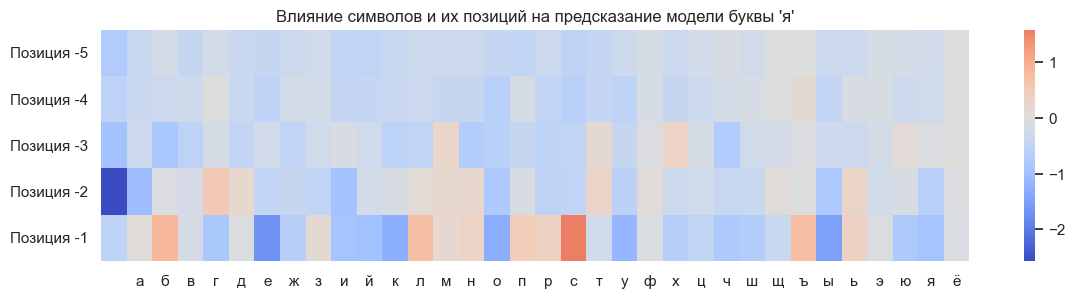

In [150]:
plt.figure(figsize=(14, 3))
sns.heatmap(
    influence,
    xticklabels=chars,
    yticklabels=[f"Позиция -{window_size-i}" for i in range(window_size)],
    cmap="coolwarm",
    center=0,
)
plt.title(f"Влияние символов и их позиций на предсказание модели буквы '{target_char}'")
plt.show()

Посмотрите также аналогичные графики для нескольких других символов.

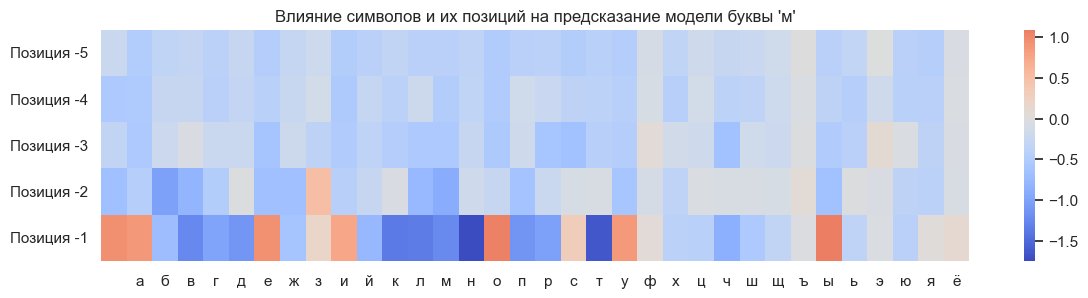

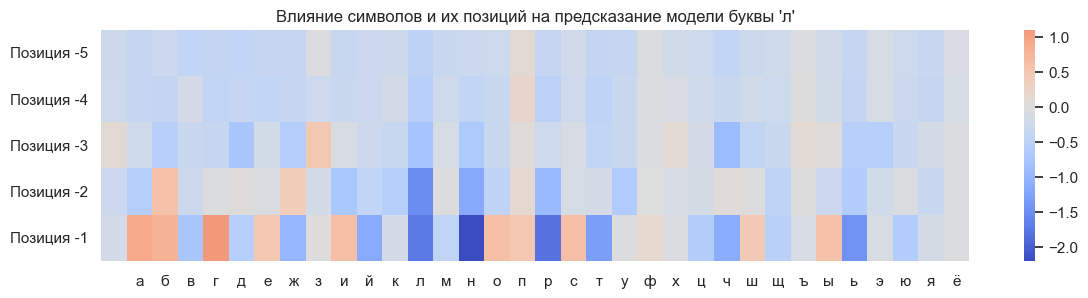

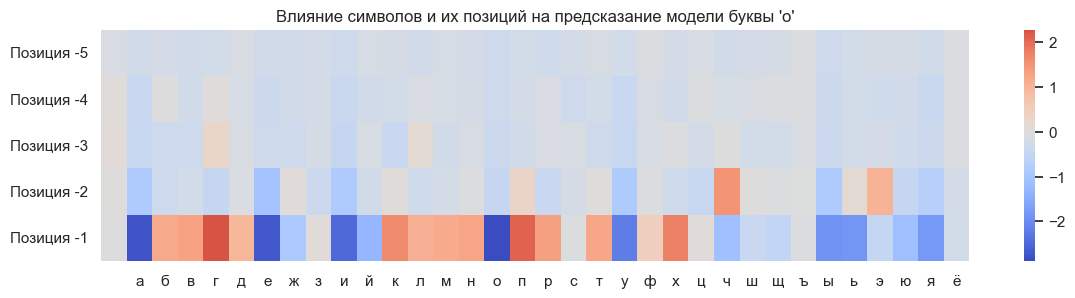

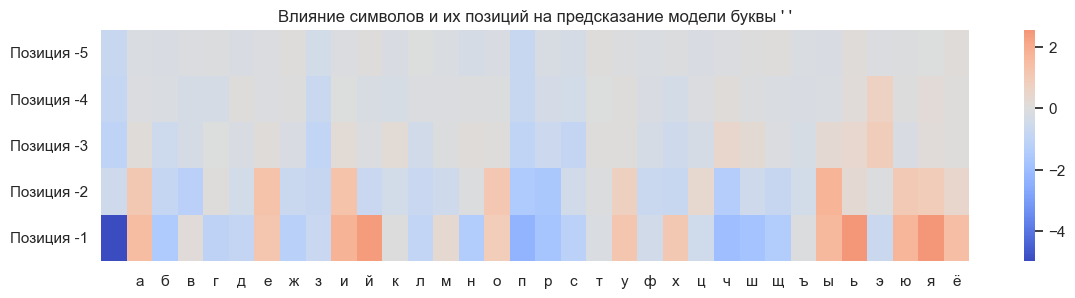

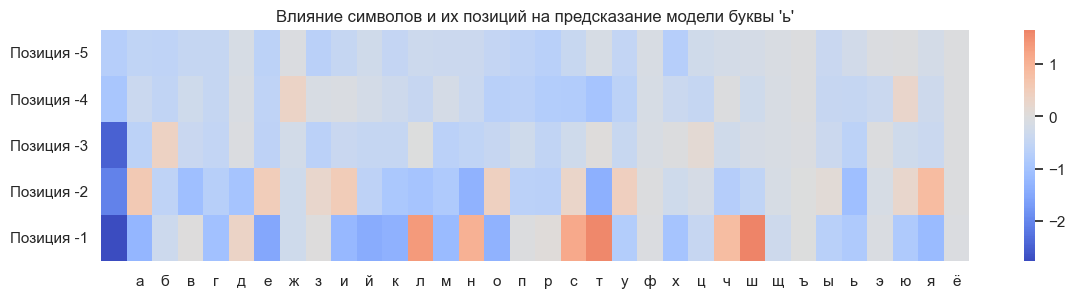

In [153]:
for target_char in [ "м", "л", "о", " ", "ь"]:
    target_idx = char_to_idx[target_char]
    influence = model.coef_[target_idx].reshape(window_size, n_chars)

    plt.figure(figsize=(14, 3))
    sns.heatmap(
        influence,
        xticklabels=chars,
        yticklabels=[f"Позиция -{window_size - i}" for i in range(window_size)],
        cmap="coolwarm",
        center=0,
    )
    plt.title(f"Влияние символов и их позиций на предсказание модели буквы '{target_char}'")
    plt.show()

Можно ли увидеть какие-то закономерности? Какие позиции влияют сильнее всего?

### Вывод по тепловым картам
Да, по тепловым картам можно заметить несколько закономерностей.

Во-первых, **самое сильное влияние на предсказание оказывает символ в позиции −1**, то есть последний символ контекста перед предсказываемой буквой. На тепловых картах именно в нижней строке чаще всего видны самые яркие по модулю значения (красные и синие области), что означает большие коэффициенты модели. Это показывает, что ближайший символ играет наиболее важную роль при предсказании следующего.

Во-вторых, **позиция −2 также оказывает заметное влияние**, однако её вклад уже меньше. Для позиций −3, −4 и −5 значения коэффициентов становятся более близкими к нулю, что говорит о меньшем влиянии более далёкого контекста.

Также видно, что **значимость зависит не только от позиции, но и от конкретного символа.** Например, для предсказания гласной **«о»** сильное влияние оказывают некоторые согласные в позиции −1, а при предсказании **пробела** заметны характерные сочетания с буквами, которые могут стоять в конце слова.

Для букв **«м» и «л»** можно увидеть, что определённые предыдущие буквы дают положительные коэффициенты, что отражает часто встречающиеся сочетания букв в русском языке.

Таким образом, тепловые карты показывают, что модель учитывает **и сами символы, и их положение в контексте**, причём **наибольший вклад в предсказание вносит ближайший символ**, а влияние более дальних позиций постепенно уменьшается.

Постройте "карту общей важности позиций". Для каждой из 5 позиций в окне посчитайте суммарный абсолютный вес (по модулю) по всем символам и всем классам, отобразите их в виде bar plot.

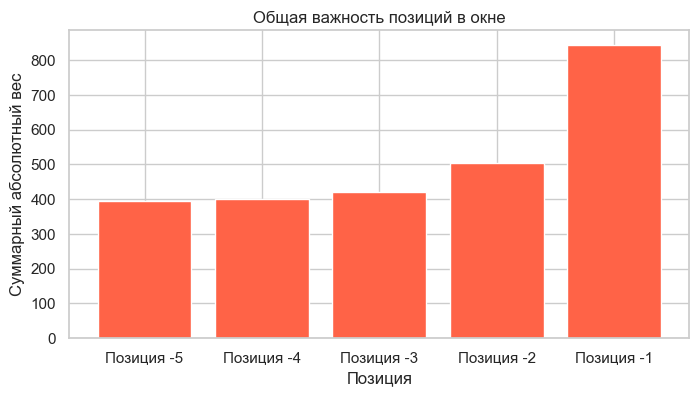

In [155]:
coef_by_position = model.coef_.reshape(n_chars, window_size, n_chars)

# Суммарная абсолютная важность каждой позиции: суммируем по всем классам и по всем символам
position_importance = np.abs(coef_by_position).sum(axis=(0, 2))

plt.figure(figsize=(8, 4))
plt.bar(
    [f"Позиция -{window_size - i}" for i in range(window_size)],
    position_importance,
    color="tomato"
)
plt.title("Общая важность позиций в окне")
plt.ylabel("Суммарный абсолютный вес")
plt.xlabel("Позиция")
plt.show()

### Выводы

Анализ коэффициентов модели показывает, что логистическая регрессия действительно использует информацию и о самих символах, и об их позиции в контекстном окне.

По тепловым картам видно, что наиболее сильные по модулю коэффициенты чаще всего сосредоточены в **последней позиции окна (позиция -1)**.  
Для позиции **-2** влияние также заметно, но уже слабее.  
Более дальние позиции (**-3, -4 и -5**) в среднем оказывают значительно меньший вклад в предсказание.

Это подтверждается и bar plot общей важности позиций:  
наибольший суммарный абсолютный вес имеет **позиция -1**, затем идёт **позиция -2**, после чего вклад постепенно уменьшается.  
То есть модель в первую очередь опирается на ближайшие к предсказываемому символу буквы.

По отдельным тепловым картам для символов **«м»**, **«л»**, **«о»**, пробела и **«ь»** видно, что влияние зависит не только от позиции, но и от конкретного символа:

- для букв **«м»** и **«л»** наиболее сильные коэффициенты сосредоточены в позиции **-1**, что говорит о сильной зависимости от предыдущей буквы;
- для гласной **«о»** на тепловой карте особенно заметны контрастные значения в ближайших позициях, что отражает характерные буквенные сочетания русского языка;
- **пробел** имеет заметное влияние, так как обозначает границу слова и часто зависит от предыдущих букв;
- для символа **«ь»** влияние распределяется между позициями **-1** и **-2**, что соответствует типичным сочетаниям мягкого знака с предыдущими согласными.

Таким образом, модель улавливает локальные закономерности русского текста:  
следующий символ сильнее всего определяется ближайшим контекстом, а влияние более дальних символов заметно слабее.

---
### Задача 2.

#### 1. От one-hot к смыслам: эмбеддинги слов

Мы переходим от предсказания букв к предсказанию целых слов!

Загрузим предобученную модель эмбеддингов **Navec** от проекта Natasha. Эти векторы были обучены на огромном корпусе текстов. В процессе обучения перебирались различные тексты и векторы слов, которые часто встречаются рядом, передвигались ближе друг к другу в многомерном пространстве.

Мы будем использовать версию `hudlit`, которая обучалась на русской художественной литературе.

Каждое слово в Navec — это вектор из 300 чисел.

In [164]:
navec_url = (
    "https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar"
)
navec_path = "navec_hudlit_v1_12B_500K_300d_100q.tar"
if not os.path.exists(navec_path):
    urllib.request.urlretrieve(navec_url, navec_path)

Загрузим модель и убедимся, что вектор слова `солнце` действительно содержит 300 чисел:

In [165]:
navec = Navec.load(navec_path)
navec["солнце"].shape

(300,)

Напишите функцию, которая принимает вектор целевого слова и возвращает $K$ самых близких к нему слов из заданного списка `vocab`. 

Меру близости мы будем оценивать через косинусное расстояние (по сути, это скалярное произведение нормированных векторов). Чем ближе косинус угла между векторами к 1, тем больше похож их смысл.

In [166]:
vocab = [
    "любовь", "сердце", "душа", "мечта", "судьба", "небо",
    "звезда", "ветер", "туман", "море", "ночь", "луна", "солнце",
    "закат", "рассвет", "тоска", "печаль", "радость", "счастье",
    "жизнь", "береза", "поле", "дорога", "тьма", "мгла",
]


def cosine_similarity(v1: np.ndarray, v2: np.ndarray) -> float:
    """Вычисляет косинусное сходство между двумя числовыми векторами.
    :param v1: Первый вектор (numpy массив).
    :param v2: Второй вектор (numpy массив).
    :return: Значение косинусного сходства (от -1.0 до 1.0)."""

    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

In [167]:
def find_nearest_in_vocab(word: str, vocab: list[str], k: int = 3) -> list[tuple[str, float]]:
    """Находит k ближайших слов к заданному слову из словаря на основе косинусного сходства.
    :param word: Целевое слово для поиска ближайших по смыслу слов.
    :param vocab: Список слов (словарь), среди которых ведется поиск.
    :param k: Количество возвращаемых ближайших соседей.
    :return: Список кортежей вида (слово, косинусное сходство), отсортированный по убыванию."""

    # Найдите k наиболее близких слов к слову word из словаря vocab.
    # Верните эти слова и расстояния в формате [(слово, расстояние), ...]
    word_vector = navec[word]

    candidates = []
    for other_word in vocab:
        if other_word == word:
            continue

        other_vector = navec[other_word]
        sim = cosine_similarity(word_vector, other_vector)
        candidates.append((other_word, sim))

    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:k]

Давайте проверим, как наша модель понимает смыслы

In [168]:
test_words = ["сердце", "солнце", "тьма"]

for word in test_words:
    print(f"Ближайшие к слову {word}:")
    print(find_nearest_in_vocab(word, vocab))

Ближайшие к слову сердце:
[('душа', np.float32(0.49851114)), ('любовь', np.float32(0.4197443)), ('тоска', np.float32(0.37497467))]
Ближайшие к слову солнце:
[('луна', np.float32(0.61312574)), ('небо', np.float32(0.6014561)), ('закат', np.float32(0.48348323))]
Ближайшие к слову тьма:
[('мгла', np.float32(0.7252577)), ('туман', np.float32(0.5133756)), ('луна', np.float32(0.46272776))]


### Вывод:

Результаты показывают, что эмбеддинги Navec действительно отражают смысловую близость слов.

Например, для слова **«сердце»** ближайшими оказались слова **«душа»**, **«любовь»** и **«тоска»**, что соответствует эмоционально-смысловому полю этого слова.  
Для слова **«солнце»** ближайшими стали **«луна»**, **«небо»** и **«закат»**, то есть слова из близкой природной и поэтической тематики.  
Для слова **«тьма»** модель выделила слова **«мгла»** и **«туман»**, которые действительно близки по смыслу.

Таким образом, предобученные эмбеддинги позволяют находить слова, близкие не по написанию, а именно по смыслу.

#### 2. Механизм Внимания (Self-Attention)

Как объяснить модели, на какое слово в контексте смотреть прямо сейчас? На самом деле Attention — это в некотором смысле "мягкий KNN"

Вместо того чтобы жестко выбирать $K$ соседей, назначая им вес 1, а остальным 0, мы берем все слова в контексте, но каждому выдаем свой "вес важности" (от 0 до 1).

> **Принцип работы**
> 
> Пусть у нас есть текущее слово-запрос $q$ и остальные слова $v_j, j\in C$ в контексте $C$ (окно). В нашей общажной модели всё это — векторы-эмбеддинги из Navec.
> 
> 1. С помощью скалярного произведения оцениваем, насколько запрос $q$ близок по смыслу к каждому слову $v_j$ в окне:
>    $$s_j = q^T  v_j$$
>    
>     *Смысл: чем ближе векторы по направлению (по смыслу), тем больше будет это число.*
> 
> 
> 2. Чтобы превратить "сырые" числа в проценты (в сумме дающие 1.0), прогоняем их через Softmax с температурой $T$, получая тем самым веса Attention:
>    $$\alpha_j = \frac{ \exp\left({\left.s_j \right/ T}\right)}{\sum_{j} \exp\left({\left.s_j \right/ T}\right)}$$
> 
> 
> 3. Итоговый вектор контекста $C$ — это взвешенная сумма векторов всех слов в этом контексте:
>    $$u_c = \sum_{j} \alpha_j v_j$$
> 
>     *Итог: получается новый вектор $u_c$, впитавший смыслы всего контекста пропорционально их важности!*


Реализуйте функцию Softmax с параметром температуры.

*Совет*: для вычислительной стабильности перед применением экспоненты вычтите из массива максимальное значение `x := x - max(x)`. Это спасет от переполнения при возведении $e$ в огромную степень, а результат после нормировки останется математически идентичным.

In [169]:
def softmax(x: np.ndarray | list[float], temperature: float = 1.0) -> np.ndarray:
    """Вычисляет функцию Softmax с применением температуры для массива значений.
    :param x: Массив сырых значений (логитов).
    :param temperature: Температура сглаживания распределения (по умолчанию 1.0).
    :return: Массив вероятностей, сумма которых равна 1.0."""
    x = np.array(x, dtype=float)
    x = x / temperature
    x = x - np.max(x)  # защита от переполнения
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

Допустим, у нас есть фраза: *"они сошлись волна и камень стихи и проза лед и пламень"*. Как слова обращают внимание друг на друга? 

Принцип Self-Attention в самом базовом виде работает следующим образом. 
Мы берем векторы всех слов и считаем скалярное произведение каждого слова с каждым. Это наша матрица "сырой похожести". В формулах Трансформера это шаг $Q K^T$ (где Query и Key — это одни и те же слова нашего предложения). Затем применяем функцию Softmax к каждой строке этой матрицы. Она превращает сырые числа в веса внимания (от 0.0 до 1.0).

*Замечание.* На самом деле $Q,K$ – это разные линейные проекции одних и тех же входных векторов слов. То есть слова в предложении одни и те же, но каждое из них представлено двумя разными векторами: "что я ищу" (вектор query) и "что я могу предложить" (key).

Давайте посчитаем это и нарисуем!



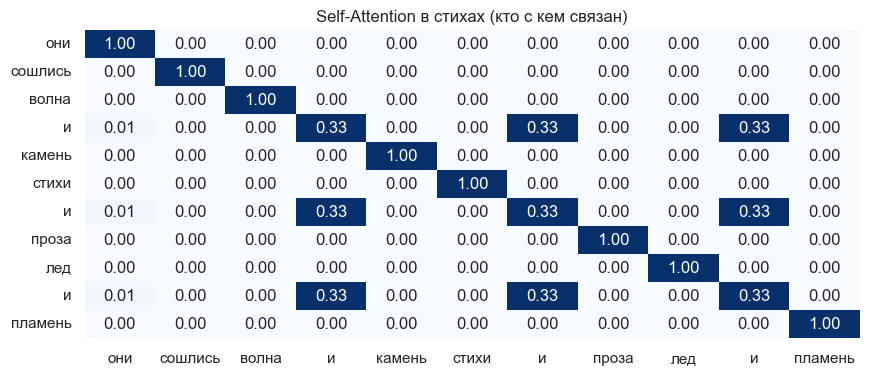

In [172]:
sentence = "они сошлись волна и камень стихи и проза лед и пламень"
words = sentence.split()

# Получаем векторы слов
vecs = np.array([navec[word] for word in words])

# Матрица попарных скалярных произведений
# Это показывает, насколько "похожи" векторы слов друг на друга
scores = vecs @ vecs.T

# Применяем Softmax
attention_matrix = np.apply_along_axis(softmax, 1, scores)

plt.figure(figsize=(10, 4))
sns.heatmap(
    attention_matrix,
    xticklabels=words,
    yticklabels=words,
    annot=True,
    fmt=".2f",
    vmax=0.2,
    cmap="Blues",
    cbar=False,
)
plt.title("Self-Attention в стихах (кто с кем связан)")
plt.yticks(rotation=0)
plt.show()

### Вывод:

На первой тепловой карте видно, что почти всё внимание сосредоточено на диагонали матрицы. 
Это означает, что каждое слово в предложении обращает внимание практически только на само себя.

Причина в том, что скалярное произведение вектора слова на самого себя значительно больше, 
чем произведение на другие слова. После применения функции Softmax эта разница усиливается, 
и самое большое значение превращается почти в 1, а остальные становятся близкими к нулю.

В результате модель практически не учитывает контекст: 
каждое слово ориентируется только на собственный вектор.

Кажется, мы увидели не то, что ожидали. Мы видим единичную матрицу (с точностью до повторяющихся слов). Наша модель стала эгоисткой — каждое слово смотрит на 99.9% только на само себя, игнорируя весь остальной контекст....

Все дело в проклятии размерности. Эмбеддинги имеют длину 300 чисел. Когда мы умножаем вектор сам на себя скалярно ($v_1^T v_1$), число получается огромным (например, 20 или 30). А скалярное произведение с другим, даже близким по смыслу словом ($v_1^T v_2$), получается сильно меньше (например, 2 или 5). 

Когда эти числа попадают в экспоненту внутри Softmax, разница становится огромной: $e^{30}$ против $e^5$. Функция Softmax делает из самого большого числа абсолютную единицу `1.0`, а всё остальное просто зануляет.

Именно поэтому авторы статьи "Attention is All You Need" придумали **Scaled Dot-Product Attention** &mdash; деление всех значений на корень из размерности вектора перед применением Softmax. Размерность у нас 300, получаем $\sqrt{300} \approx 17.3$.

В нашей функции `softmax` уже есть параметр `temperature`, который делает ровно это. Добавьте `temperature=20.0`, чтобы сгладить распределение и заставить слова смотреть по сторонам!

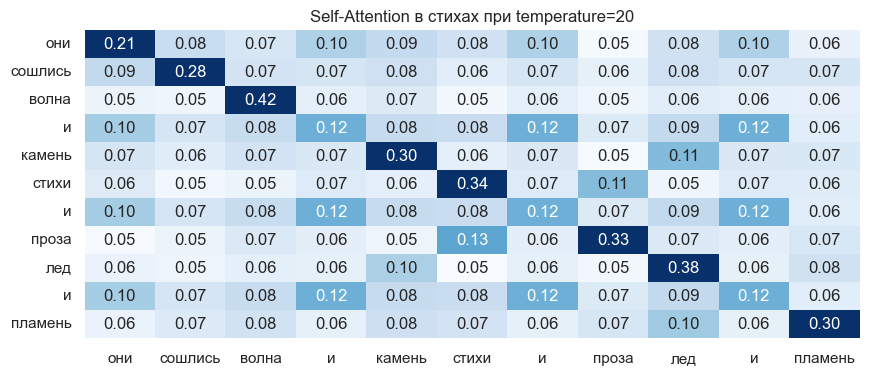

In [174]:
attention_matrix = np.apply_along_axis(lambda row: softmax(row, temperature=20.0), 1, scores)

plt.figure(figsize=(10, 4))
sns.heatmap(
    attention_matrix,
    xticklabels=words,
    yticklabels=words,
    annot=True,
    fmt=".2f",
    vmax=0.2,
    cmap="Blues",
    cbar=False,
)
plt.title("Self-Attention в стихах при temperature=20")
plt.yticks(rotation=0)
plt.show()

Посмотрите на новый график. Какие слова (кроме самих себя) оказались сильно связаны между собой по смыслу в понимании модели?

### Ответ:

После увеличения температуры распределение внимания стало более сглаженным. 
Теперь слова обращают внимание не только на самих себя, но и на другие слова в предложении.

На графике можно заметить несколько смысловых связей между словами. 
Например, относительно заметна связь между словами **«стихи»** и **«проза»**, 
которые относятся к одной тематике литературы.

Также наблюдается связь между словами **«камень»** и **«лед»**, 
а также между **«лед»** и **«пламень»**, что отражает образы природных явлений.

Таким образом, при увеличении температуры механизм attention начинает учитывать 
смысловые отношения между словами, а не только их собственные векторы.

#### 3. Собираем всё вместе: языковая модель на основе Attention

Сам по себе механизм Attention не умеет предсказывать следующее слово. Он лишь создает идеальное математическое представление контекста — вектор контекста.  Это просто взвешенная сумма векторов слов контекста, где весами выступают те самые вероятности из матрицы Attention. 
Получив этот супер-информативный вектор, мы передадим его в нашу обычную логистическую регрессию для классификации (предсказания следующего слова). Примерно так работают слои `Linear + Softmax` в конце архитектуры GPT!

Для начала, ограничим наш словарь. Предсказывать все уникальные слова из стихов для логистической регрессии будет сложно, поскольку классов будут десятки тысяч. Оставим только те слова, которые встречаются хотя бы 10 раз. Редкие слова предсказывать не будем.

In [178]:
min_count = 10  # Задаем порог: слово должно встретиться минимум N раз
window_size = 4  # количество предыдущих слов, на основе которых будем предсказывать следующее

In [181]:
# Собираем все слова в один список
all_words = []
for text in data_sample["text"]:
    all_words.extend(text.split())

# Считаем, сколько раз встречается каждое слово
counts = Counter(all_words)

# Оставляем только частые слова для предсказания
vocab_words = [word for word, count in counts.items() if count >= min_count]

# Создаем  word_to_idx только для частых слов
# Это будет наш список классов для классификации
word_to_idx = {word: i for i, word in enumerate(vocab_words)}

print(f"Всего слов в текстах: {len(counts)}")
print(f"Осталось слов после фильтрации (размер словаря): {len(word_to_idx)}")

Всего слов в текстах: 96060
Осталось слов после фильтрации (размер словаря): 7513


Теперь соберем наш датасет для регрессии следующим образом.
1. Идем по тексту "окном" из 4 слов. Целевая метка $Y$ — 5-е слово.
2. Берем эмбеддинги этих 4 слов из Navec.
3. Слово, которое стоит прямо перед пропуском, будет нашим "запросом" (query). Мы хотим понять: *с учетом этого последнего слова, на что еще в контексте нужно обратить внимание?*
4. Считаем скалярные произведения query со всеми словами в окне.
5. Применяем Softmax с температурой 20, получая тем самым веса Attention.
6. Умножаем матрицу векторов на эти веса — получаем единый кектор контекста. Это и будут наши признаки $X$.

In [182]:
X_attn = []
y_words = []

for text_string in tqdm(data_sample["text"]):
    words = text_string.split()

    if len(words) <= window_size:
        continue

    for i in range(len(words) - window_size):
        context = words[i : i + window_size]
        target = words[i + window_size]

        # Целевое слово должно быть популярным (быть в нашем новом словаре)
        if target not in word_to_idx:
            # Пропускаем, не будем учить модель предсказывать редкое слово
            continue

        # Слова контекста должны быть известны Navec (чтобы взять векторы)
        try:
            vecs = np.array([navec[w] for w in context])
        except KeyError:
            # Если хоть одно слово неизвестно Navec - пропускаем
            continue

        # Посчитайте вектор Attention
        query = vecs[-1]
        scores = vecs @ query
        
        weights = softmax(scores, temperature=20.0)
        context_vector = weights @ vecs

        X_attn.append(context_vector)
        y_words.append(word_to_idx[target])

X_attn = np.array(X_attn)
y_words = np.array(y_words)

print(f"Итоговая размерность X: {X_attn.shape}")
print(f"Итоговая размерность y: {y_words.shape}")

  0%|          | 0/5000 [00:00<?, ?it/s]

Итоговая размерность X: (412489, 300)
Итоговая размерность y: (412489,)


Матрица признаков имеет размер `(n, 300)`, то есть мы сжали 4 слова в один вектор размером 300 чисел. Но благодаря Attention, в отличие от простого усреднения, этот вектор динамически подчеркнул самые важные по смыслу слова.

Теперь обучим логистическую регрессию предсказывать индекс следующего слова по этому вектору контекста.

In [183]:
model = SGDClassifier(
    loss="log_loss",
    max_iter=200
)

model.fit(X_attn, y_words)

,"loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",200
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",-1


Финальный штрих. Напишем функцию генерации текста, которая будет использовать нашу обученную Attention-модель.

Процесс генерации на каждом шаге выглядит следующим образом.
1. Берем последние 4 слова текста и достаем их эмбеддинги.
2. Вычисляем вектор контекста.
3. Передаем его в логистическую регрессию для предсказания вероятностей.
4. Применяем температуру сэмплирования к вероятностям и выбираем следующее слово.

Допишите недостающие части кода в функции.

In [185]:
def generate_with_attention(
    seed_words: list[str], length: int = 10, temperature: float = 1.0
) -> str:
    """Генерирует текст по словам, используя механизм Attention и логистическую регрессию.
    :param seed_words: Список начальных слов для старта генерации.
    :param length: Количество слов для генерации.
    :param temperature: Температура для генерации.
    :return: Итоговая сгенерированная строка текста."""

    current_words = seed_words.copy()

    # Создадим обратный словарь
    idx_to_word = {i: w for w, i in word_to_idx.items()}

    for _ in range(length):
        # Контекст
        context = current_words[-window_size:]

        # Если слово незнакомо, берем нулевой вектор
        vecs = np.array([navec[w] if w in navec else np.zeros(300) for w in context])

        # Механизм Внимания (как раньше)
        query = vecs[-1]
        scores = vecs @ query
        weights = softmax(scores, temperature=20.0)  # здесь temperature=20, это не температура генерации!
        context_vector = weights @ vecs 
        
        # Выполните оценку вероятностей, примените температуру и сгенерируйте следующее слово
        probs = model.predict_proba(context_vector.reshape(1, -1))[0]

        probs = probs ** (1 / temperature)
        probs = probs / probs.sum()

        next_word_idx = np.random.choice(len(probs), p=probs)

        next_word = idx_to_word[next_word_idx]
        current_words.append(next_word)

    return " ".join(current_words)

Барабанная дробь! Запускаем нашу GPT-0.001.

In [186]:
# Параметры генерации
length = 20
temperatures = [0.5, 1.0, 2.0]

examples = ["буря мглою небо кроет", "белеет парус одинокий в тумане моря"]


for i, text in enumerate(examples, 1):
    seed_words = text.split()
    for temp in temperatures:
        result = generate_with_attention(seed_words, length=length, temperature=temp)
        print(f"T={temp}: {result}")

T=0.5: буря мглою небо кроет и и на меня не на берегу я сейчас я вижу не за тобой с тобой с ним тобой и
T=1.0: буря мглою небо кроет и мной не тень долго по ты родины тем меня меня не я к брат я что за не хочу
T=2.0: буря мглою небо кроет слезами трудно до весы много век горд чтоб богатый белый и ноги ваша вечно века точно от слов тьму готов
T=0.5: белеет парус одинокий в тумане моря в тишине под и в все как себя что все я я знаю хочу не не не знаю не не
T=1.0: белеет парус одинокий в тумане моря и в огнем в дороге дни мы успели из назад с вами собой с ними тобой бы ней скажи мальчик
T=2.0: белеет парус одинокий в тумане моря час дым душа старый едва но тень пока поет годов ты водою то привета звуках круги меня так часто стрела


Оцените результат:
* Насколько осмысленными получаются генерации по сравнению с посимвольной моделью из первой части?
* Удается ли модели сохранять тему заданных стартовых слов?
* Что можно было бы улучшить в нашей "общажной" модели, если бы у нас было больше вычислительных мощностей?

### Оценка результатов генерации

**1. Насколько осмысленными получаются генерации по сравнению с посимвольной моделью?**

По сравнению с посимвольной моделью из первой части, генерации на уровне слов выглядят более осмысленными.
Модель оперирует уже словами и использует векторные представления слов, поэтому лучше сохраняется структура предложений и появляются более реалистичные словосочетания.

При небольшой температуре (**T = 0.5**) модель генерирует наиболее связный текст.
В продолжениях появляются грамматически похожие конструкции и типичные слова из поэтических текстов.
Но иногда заметны повторения слов и простые фразы, что связано с тем, что модель выбирает наиболее вероятные варианты.

При температуре **T = 1.0** текст становится более разнообразным.
Появляется больше различных слов и выражений, но иногда структура предложений становится менее строгой.

При высокой температуре (**T = 2.0**) генерация становится значительно более случайной:
появляются неожиданные слова и менее связные фразы.
Это происходит, потому что распределение вероятностей становится более плоским, и модель чаще выбирает менее вероятные варианты.

**2. Удается ли модели сохранять тему заданных стартовых слов?**

Модель частично сохраняет тему начальных слов.
Например, при старте с фразами из известных стихотворений («буря мглою небо кроет», «белеет парус одинокий») в продолжении часто появляются слова, связанные с природой, чувствами или описанием состояния.

Таким образом, модель действительно научилась улавливать некоторые закономерности языка,
но из-за небольшого окна (4 слова) и простой линейной модели она всё ещё не всегда поддерживает долгую смысловую связность текста.

**3. Что можно было бы улучшить, если бы у нас было больше вычислительных мощностей?**

- Увеличить размер окна контекста, это позволило бы модели учитывать более длинные зависимости в тексте.

- Заменить логистическую регрессию на полноценный Transformer с обучаемыми матрицами проекций Q, K, V
  и механизмом multi-head attention — то, что лежит в основе современных LLM вроде GPT.

- Масштабировать модель: больше данных и больше параметров. Например, как показал путь от GPT-1 (117M)
  до GPT-3 (175 млрд параметров) — качество генерации растёт вместе с масштабом.

- Добавить инструктивное обучение (instruction-tuning) и обучение с учётом человеческих предпочтений (RLHF), чтобы модель не просто продолжала текст,
  а училась давать полезные ответы — именно это превратило базовый GPT в ChatGPT.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД